# Customer Churn Prediction

## 1. Project Overview & Business Problem
* **Objective:** Predict customer churn for a telecommunications provider to identify high-risk accounts and enable proactive retention strategies.
* **Dataset:** Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`) with 7,043 customer records and 21 attributes/variables.
* **Target Variable:** `Churn` (Yes / No).

### 1.1 Data Details

The dataset contains **7,043 customer accounts** described across **21 attributes**, which can be structured into four distinct analytical dimensions:

* **Customer Demographics:**
  * `customerID`: Unique identifier for each account.
  * `gender`, `SeniorCitizen`, `Partner`, `Dependents`: Personal and household characteristics.
* **Account & Contract Terms:**
  * `tenure`: Number of months the customer has stayed with the company.
  * `Contract`: Contract commitment type (*Month-to-month*, *One year*, *Two year*).
  * `PaperlessBilling`: Whether the customer opts for digital billing (*Yes* / *No*).
  * `PaymentMethod`: Payment channel (*Electronic check*, *Mailed check*, *Bank transfer (automatic)*, *Credit card (automatic)*).
* **Subscribed Services:**
  * Core Connectivity: `PhoneService`, `MultipleLines`, `InternetService` (*DSL*, *Fiber optic*, *No*).
  * Add-on & Security Services: `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`.
* **Financial & Target Metrics:**
  * `MonthlyCharges`: Current amount billed to the customer each month (continuous).
  * `TotalCharges`: Cumulative charges over the customer's lifespan (requires type casting from string to float).
  * `Churn`: Target variable indicating whether the customer left within the last month (*Yes* / *No*).

### 1.2 Expected relationship between Churn and other attributes

Our target variable is `Churn`, so we want to understand the relationship between it and other attributes. For this, we are going to list some hypotheses about their relationship. To start, we don't believe that `Churn` is affected by `gender`, `Partner` or `PaperlessBilling`.

For the rest:
* `SeniorCitizen` and `Dependents` should have a lower Churn rate, older clients probably don't care too much about the service as long as it is functional and clients with `Dependents` are more reluctant to change providers or stop using the service, because they have more people under them that use the service. 
* `tenure`: the higher the `tenure`, the lower the Churn rate. Clients who have been using the service for a longer time, don't have a lot of incentives to leave the company. It could be that they are satisfied or resistant to change.
* `Contract`: the Churn rate from someone with a *Month-to-month* contract is higher than someone with a *One year* or *Two year* contract.
* `PaymentMethod`: Someone with a *Credit Card* and *Bank transfer* should have a lower rate than the others, since the process for the payment is automatic, there's no friction. *Electronic check* and *Mailed check* are manual processes, so they should have a higher Churn rate.
* `MonthlyCharges`: The higher the charge, the higher the Churn rate.
* `TotalCharges`: The higher the amount, the lower the Churn rate. With a higher `TotalCharges`, it probably means that you have been using the service more months or years, so lower Churn rate.

About the *Subscribed Services*, in this case it would depend if the company gives a good service. If a company gives a bad service in one or all categories, it probably has a high Churn rate. Also, for `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV` and `StreamingMovies`, there could be a relationship between more add-ons and a lower Churn rate, since you have to replace more services.

## 2. Loading libraries and data

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import textwrap
import math
import re
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             recall_score, precision_score, f1_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay
from pathlib import Path
from sklearn.preprocessing import SplineTransformer
Path('images').mkdir(exist_ok=True)

In [2]:
# Data
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

## 3. Initial Inspection
Previewing the schema and first records.

In [3]:
print(f"Shape: {df.shape} | Unique customerID: {df['customerID'].is_unique} | Duplicated rows: {df.duplicated().sum()}")

Shape: (7043, 21) | Unique customerID: True | Duplicated rows: 0


In [4]:
# First 5 customers of the data with the 21 attributes.
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Information for each attribute from our dataset.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

The first thing that comes to mind is why the `TotalCharges` variable is an `object` type when it should be `float64`.

In [6]:
# Looking for missing values in any attribute.
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

No explicit NaN values, but blanks may still hide in text columns.

In [7]:
df[df['TotalCharges'].str.strip() == '']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


As we can see, it seems like when `tenure` is equal to 0 `TotalCharges` is a blank space. This makes sense, since `tenure` 0 means that the customer has not completed their first billing cycle. We will check if this relationship holds.

## 4. Data Wrangling

In [8]:
# Blank TotalCharges must match tenure == 0 exactly (both directions)
blank_mask = df['TotalCharges'].str.strip() == ''
tenure_zero_mask = df['tenure'] == 0

print(f'Blank TotalCharges: {blank_mask.sum()} | tenure == 0: {tenure_zero_mask.sum()}')
assert (blank_mask == tenure_zero_mask).all()

Blank TotalCharges: 11 | tenure == 0: 11


We confirm that this is the case. When `tenure` is equal to 0, `TotalCharges` is a blank space. We will change its format to float64 now. 

In [9]:
# Turn 'TotalCharges' to float64, coercing any non numeric value to missing value.  
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Coerce should only have affected the blanks, nothing else
assert df['TotalCharges'].isna().sum() == blank_mask.sum()

# Filling every missing value to 0.
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Check to see if changes affected 'TotalCharges'
assert (df.loc[tenure_zero_mask, 'TotalCharges'] == 0).all()

# Show table
display(df.loc[tenure_zero_mask, ['customerID', 'tenure', 'TotalCharges', 'Churn']])

,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,0.0,No
753,3115-CZMZD,0,0.0,No
936,5709-LVOEQ,0,0.0,No
1082,4367-NUYAO,0,0.0,No
1340,1371-DWPAZ,0,0.0,No
3331,7644-OMVMY,0,0.0,No
3826,3213-VVOLG,0,0.0,No
4380,2520-SGTTA,0,0.0,No
5218,2923-ARZLG,0,0.0,No
6670,4075-WKNIU,0,0.0,No


We have transformed every blank space to a 0 in `TotalCharges` when `tenure` is equal to 0. It is fine to leave this as 0, since clients with `tenure` = 0 haven't completed a billing cycle yet.

We will also map `SeniorCitizen` to Yes and No to keep consistency with the other categorical attributes.

In [10]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['SeniorCitizen'].head()

0    No
1    No
2    No
3    No
4    No
Name: SeniorCitizen, dtype: str

## 5. Exploratory Data Analysis

### 5.1. Churn percentage

,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


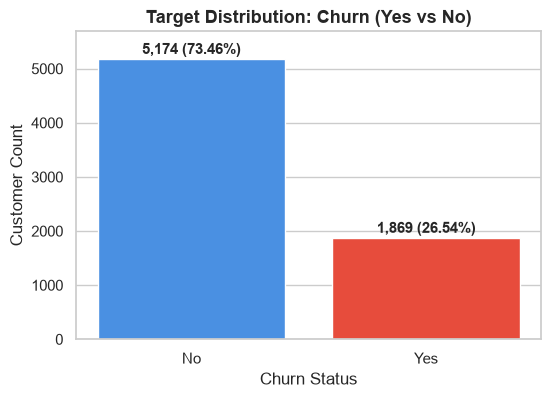

In [11]:
# Plot settings
sns.set_theme(style='whitegrid')
order = ['No', 'Yes']
palette = {'No': '#4A90E2', 'Yes': '#E74C3C'}

# Summary table
churn_summary = (
    df['Churn'].value_counts()
    .reindex(order)
    .to_frame('count')
    .assign(percentage=lambda x: (x['count'] / x['count'].sum() * 100).round(2))
)
display(churn_summary)

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(churn_summary.index, churn_summary['count'], color=[palette[k] for k in order])
ax.bar_label(
    ax.containers[0],
    labels=[f'{n:,} ({p:.2f}%)' for n, p in zip(churn_summary['count'], churn_summary['percentage'])],
    padding=1.5, fontsize=11, fontweight='bold'
)
ax.margins(y=0.10)
ax.set_title('Target Distribution: Churn (Yes vs No)', fontsize=13, weight='bold')
ax.set_xlabel('Churn Status')
ax.set_ylabel('Customer Count')
ax.xaxis.grid(False)
plt.show()

We can see that for the entire data, more than 25% of clients churn. 26.54% is our base number to compare against other cases.

### 5.2. Churn percentage by gender, dependents and partner

In [12]:
# Defining a function to filter the attribute plot by another attribute
def plot_churn_by(col, data=None, title_suffix='', ax=None, show_table=False):
    data = df if data is None else data

    # Summary table
    summary = (
        data.groupby(col)['Churn']
        .value_counts()
        .rename('count')
        .reset_index()
        .assign(percentage=lambda x: (x['count'] / x.groupby(col)['count'].transform('sum') * 100).round(2))
    )
    if show_table:
        display(summary)

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(7, 4.5))

    # Plot
    sns.barplot(data=summary, x=col, y='percentage', hue='Churn', hue_order=order, palette=palette, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f%%', padding=1.5, fontsize=11, fontweight='bold')
    ax.margins(y=0.10)
    ax.set_title(f'Churn Rate by {col}{title_suffix}', fontsize=13, weight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel(f'Percentage within {col} (%)')
    ax.legend(title='Churn')
    # Wrap long category labels so they do not overlap
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([textwrap.fill(t.get_text(), 14) for t in ax.get_xticklabels()])
    if standalone:
        plt.show()

#### 5.2.1 By gender

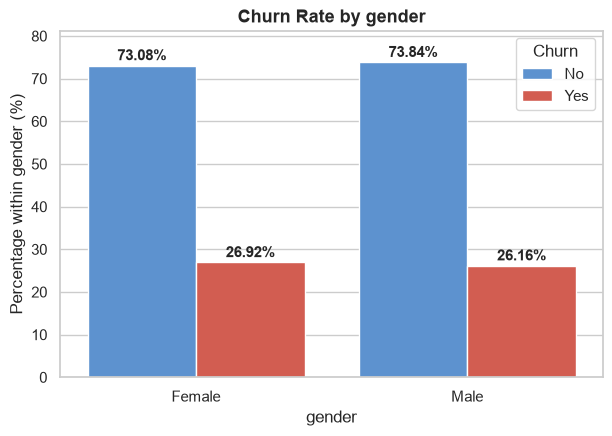

In [13]:
plot_churn_by('gender')

We can see that there's not much of a difference in the percentage when they are grouped by gender. Male and Female churn in almost the same proportion and they look very much the same as when we look the churn percentage as a whole. This could indicate that our hypothesis is right, gender doesn't affect the churn rate. 

#### 5.2.2 By dependents

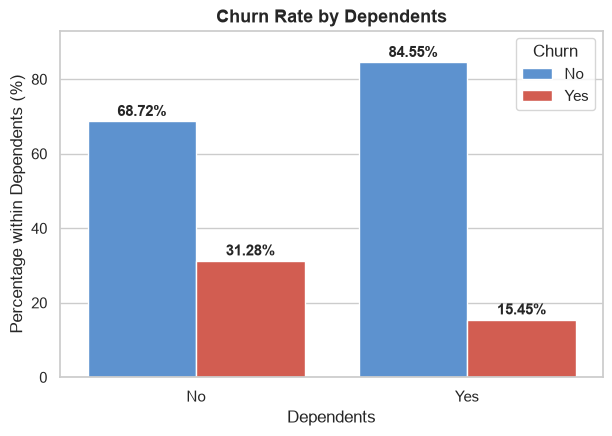

In [14]:
plot_churn_by('Dependents')

Just like we predicted, clients with dependents churn at a lower rate than those who don't have dependents.

#### 5.2.3 By partner

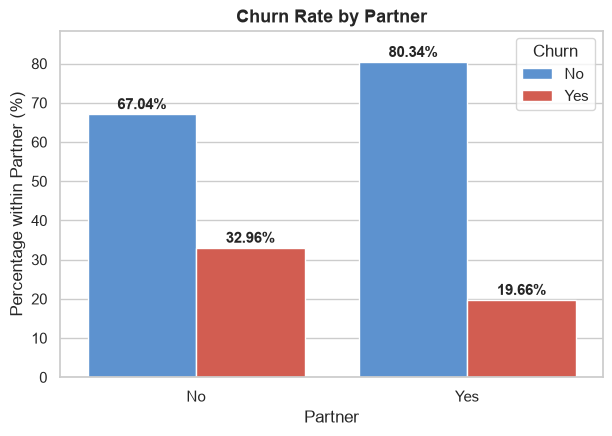

In [15]:
plot_churn_by('Partner')

Here we might be wrong in our assumption. Clients with a partner churn at a lower rate than the ones without it. This might be because clients with a partner have a higher chance to live with kids or have dependents, so they also fall in the other category of clients with dependents. We will look into this.

In [16]:
pd.crosstab(df['Partner'], df['Dependents'], normalize='index').round(2)

Dependents,No,Yes
Partner,,
No,0.90,0.10
Yes,0.49,0.51


We are right, of the clients without a partner only 10% have dependents, while of clients with a partner 51% have dependents. Let's see how our churn rate changes taking this into consideration.

#### 5.2.4 Churn percentage by partner with and without dependents

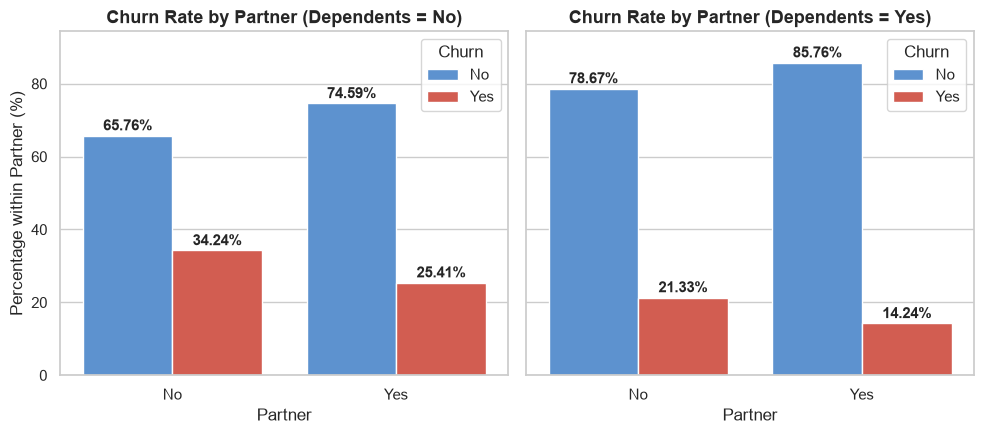

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
plot_churn_by('Partner', data=df[df['Dependents'] == 'No'],
              title_suffix=' (Dependents = No)', ax=axes[0])
plot_churn_by('Partner', data=df[df['Dependents'] == 'Yes'],
              title_suffix=' (Dependents = Yes)', ax=axes[1])
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

For `Dependents` = No, we see that clients with a partner have a similar churn rate to the general clients. We might have found one of the explanations for this particular group. Clients with no partner have a similar churn rate with or without the dependents filter. This makes sense, since 90% of them have no dependents, so the filter doesn't change much. Also, for people with `Dependents` = Yes, we see that they tend to churn less than every other group, which goes in the direction of our hypothesis.

Finally, our hypothesis for partner might be incorrect. When we are not filtering by dependents, there's a difference of ~13pp, and while considering dependents we have a difference of ~9pp and ~7pp. While dependents explain some of the effects of partner over the churn rate, there is a percentage that is not explained by it and may be effect of having a partner.

### 5.3. Churn percentage by senior citizen, billing type and contract type

#### 5.3.1 By senior citizen

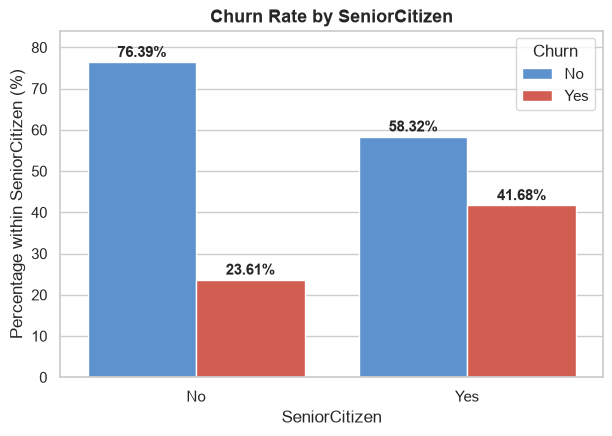

In [18]:
plot_churn_by('SeniorCitizen')

For this case we are completely wrong, we have a ~18pp difference in churn rate when a client is a senior citizen. Senior citizens do churn at higher rates.

#### 5.3.2 By paperless billing

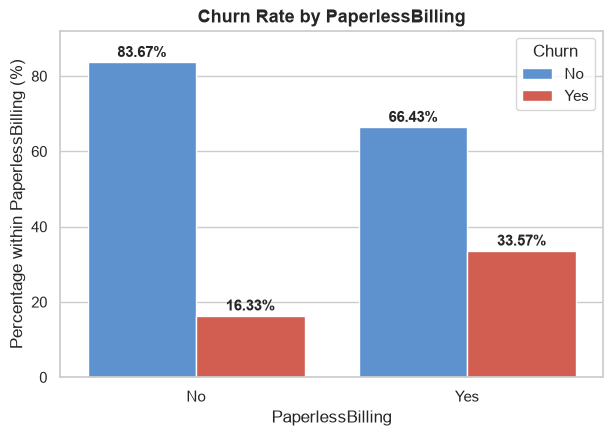

In [19]:
plot_churn_by('PaperlessBilling')

We are also wrong in this case, we have a difference of ~17pp here. People with a digital billing tend to churn more than those who opt out.

#### 5.3.3 By contract

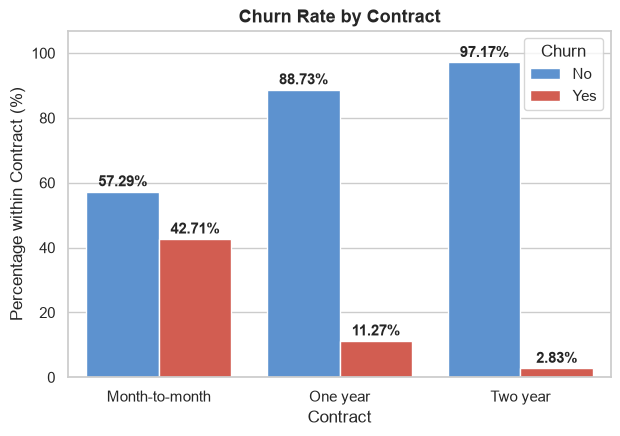

In [20]:
plot_churn_by('Contract')

This is by far the most interesting attribute that we have explored. The churn rate for one and two year contracts is really low. Two year contracts are ~24pp lower considering all the clients. In contrast, Month-to-month contracts are ~16pp higher than our base percentage, 26.54%. This might be the biggest factor affecting churn rates. We hypothesize that the churn rate would be higher in month-to-month contracts, but we didn't expect such a large difference. Coincidentally, the percentage of churn rate of senior citizens is very close to that of Month-to-month contracts. Maybe senior citizens have more month-to-month contracts than non-senior citizens. Let's see the table.

In [21]:
pd.crosstab(df['SeniorCitizen'], df['Contract'], normalize='index').round(2)

Contract,Month-to-month,One year,Two year
SeniorCitizen,,,
No,0.52,0.22,0.26
Yes,0.71,0.17,0.13


71% of senior citizens have a Month-to-month contract, while only 52% of the rest of the clients. This might be part of why senior citizens churn at higher rates.

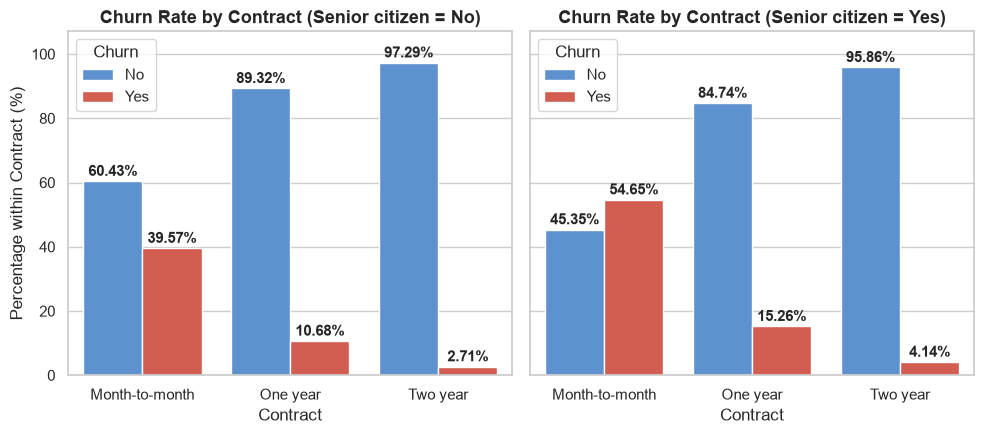

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
plot_churn_by('Contract', data=df[df['SeniorCitizen'] == 'No'],
              title_suffix=' (Senior citizen = No)', ax=axes[0])
plot_churn_by('Contract', data=df[df['SeniorCitizen'] == 'Yes'],
              title_suffix=' (Senior citizen = Yes)', ax=axes[1])
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

Just like we predicted, the type of contract does have some effect on the churn rate by senior citizens, but it is probably not the only one, since even when only looking at senior citizens with a Month-to-month contract, they do churn ~12pp more often than when looking at all the clients. For clients that are not senior, we see that they churn in similar percentages compared to all the clients.

#### 5.3.4 Churn percentage by phone and internet service

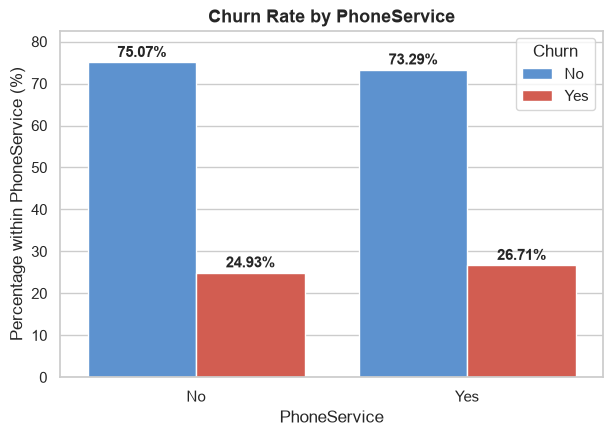

In [23]:
plot_churn_by('PhoneService')

We can see that there's not a big difference for a client to churn based on the phone service. There's only a difference of ~2pp between them and they are very close to the base percentage.

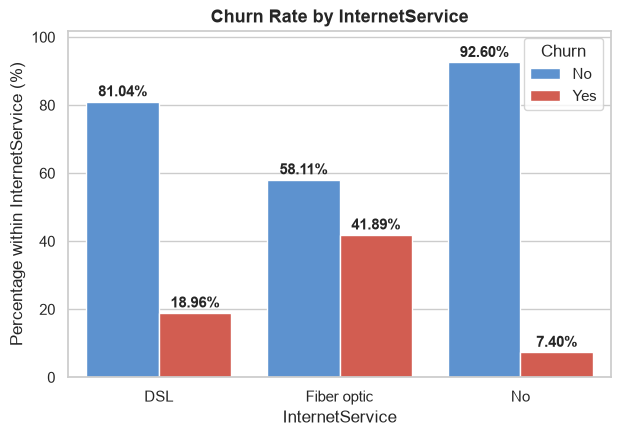

In [24]:
plot_churn_by('InternetService')

This one is interesting too, we see that fiber optic has a higher churn rate. This could be related to the other attributes, maybe fiber optic is the one most prone to be offered as a Month-to-month contract and since senior citizens are offered more month-to-month contracts, this could also lead to senior citizens having more fiber optic than the rest. Let's see the percentage of contracts that are Month-to-month and we will compare them to the percentage of Month-to-month contracts given that they have fiber optic.

In [25]:
pd.crosstab(df['InternetService'], df['Contract'], normalize='index').round(2)

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,0.51,0.24,0.26
Fiber optic,0.69,0.17,0.14
No,0.34,0.24,0.42


69% of fiber optic contracts are Month-to-month, while DSL 51% and No 34%. It probably has some effect on the churn rate that we see in fiber optic. We will see how much of those fiber optic contracts are for senior citizens.

In [26]:
pd.crosstab(df['SeniorCitizen'], df['InternetService'], normalize='index').round(2)

InternetService,DSL,Fiber optic,No
SeniorCitizen,,,
No,0.37,0.38,0.25
Yes,0.23,0.73,0.05


We were right, of the total of senior citizens, 73% of them have fiber optic. Like we said, this higher churn rate for fiber optic is in part explained by the contract type, but there's also a chance of the quality of the service not being good. This is something that unfortunately falls outside the scope of this dataset, but could be relevant to other departments of the company. Let's have a closer look between the relationship of `InternetService` with `PhoneService` and `MultipleLines`.

In [27]:
churn_pct = (df['Churn'] == 'Yes') * 100

display(pd.crosstab(df['InternetService'], df['PhoneService']))
display(churn_pct.groupby([df['InternetService'], df['PhoneService']])
        .agg(clients='size', churn_pct='mean').round(1))

# MultipleLines (only meaningful with phone service), by internet type
with_phone = df['PhoneService'] == 'Yes'
display(churn_pct[with_phone].groupby([df.loc[with_phone, 'InternetService'], df.loc[with_phone, 'MultipleLines']])
        .agg(clients='size', churn_pct='mean').round(1))

PhoneService,No,Yes
InternetService,,
DSL,682,1739
Fiber optic,0,3096
No,0,1526


clients  churn_pct
InternetService PhoneService                    
DSL             No                682       24.9
                Yes              1739       16.6
Fiber optic     Yes              3096       41.9
No              Yes              1526        7.4

clients  churn_pct
InternetService MultipleLines                    
DSL             No                1048       20.6
                Yes                691       10.6
Fiber optic     No                1158       45.8
                Yes               1938       39.6
No              No                1184        8.7
                Yes                342        2.9

`PhoneService` shows no overall difference, but it is not independent of `InternetService`: clients without phone service are all DSL. Within DSL they churn more (24.9% vs 16.6%), and the controlled model reverses that direction (OR 0.63). `MultipleLines` shows a similar reversal. Both are conditional contrasts tied to the service structure, so they are not interpreted in isolation.

#### 5.3.5 Payment method and add-on services

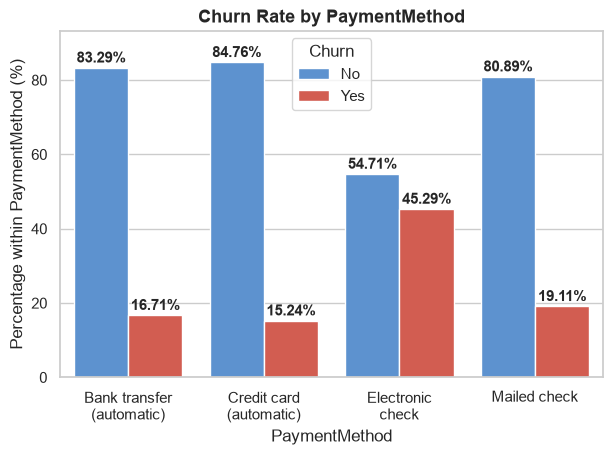

,clients,churn_pct
n_addons,,
0,693,52.2
1,966,45.8
2,1033,35.8
3,1118,27.4
4,852,22.3
5,571,12.4
6,284,5.3


In [28]:
plot_churn_by('PaymentMethod')

addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
internet = df[df['InternetService'] != 'No']
n_addons = (internet[addon_cols] == 'Yes').sum(axis=1)
display(internet.assign(n_addons=n_addons).groupby('n_addons')['Churn']
        .agg(clients='size', churn_pct=lambda s: (s == 'Yes').mean() * 100).round(1))

Electronic check clients churn at 45.3%, versus 15-19% for the other three methods. Among clients with internet service, churn falls steadily with the number of add-ons, from 52.2% with none to 5.3% with all six. The model in 7.3 will show that this pattern is not equal across add-ons.

### 5.4. Tenure, monthly charges and total charges

#### 5.4.1 Variables distribution by churn

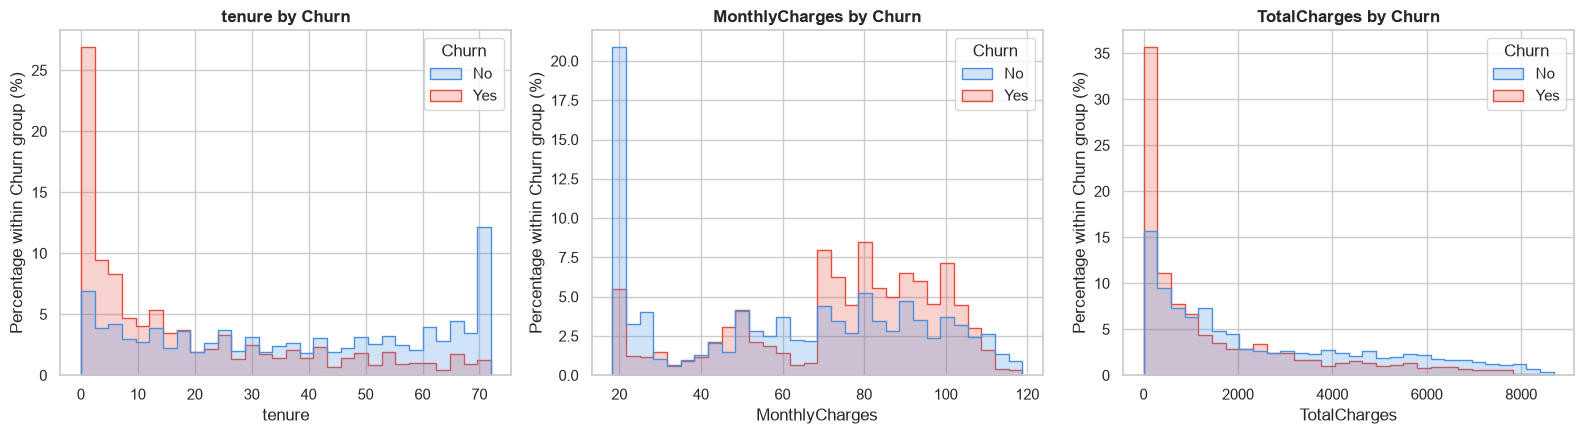

In [29]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='Churn', hue_order=order, palette=palette,
                 stat='percent', common_norm=False, element='step', bins=30, ax=ax)
    ax.set_title(f'{col} by Churn', fontsize=12, weight='bold')
    ax.set_ylabel('Percentage within Churn group (%)')
plt.tight_layout()
plt.show()

We can see that churn rates are higher the lower tenure that a client has. For monthly charges, the churn rate is lower with a lower monthly charge, but we can see that at around $110 this changes, with clients with a higher monthly charge having a lower churn rate. Finally, for total charges we can see that the lower the amount, the higher the churn rate, this is because clients leave in the first months and because the higher the monthly rate, higher the churn rate, so clients with low tenure and high monthly charges are probably represented in the beginning of the curve, while the ones that stay longer are represented in the rest of the curve.

#### 5.4.2 Correlation between variables and churn

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
Churn,-0.35,0.19,-0.20,1.00


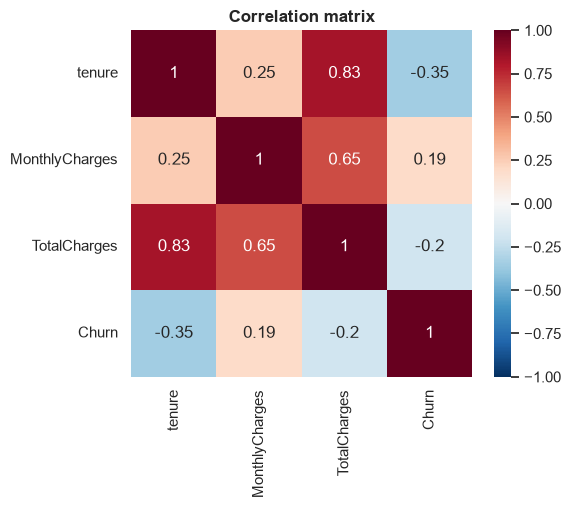

In [30]:
corr = df[num_cols].assign(Churn=(df['Churn'] == 'Yes').astype(int)).corr().round(2)
display(corr)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation matrix', fontsize=12, weight='bold')
plt.show()

In [31]:
# Correlation tenure * monthly charges and Total charges
display(pd.DataFrame(
    {'Correlation': [df['TotalCharges'].corr(df['tenure'] * df['MonthlyCharges'])]},
    index=['TotalCharges vs tenure × MonthlyCharges']
).round(4))

,Correlation
TotalCharges vs tenure × MonthlyCharges,0.9996


Looking at the linear correlation between variables, the results are somewhat predictable. The longer the tenure, the lower the churn rate and the higher the monthly charge the higher the churn rate. In total charges we see that there's a negative correlation, this is because, just like we saw in the histogram, higher churn rates concentrate in lower values. Also, tenure and monthly charges have a high correlation with total charges, this isn't 1 because sometimes the monthly charge changes.

#### 5.4.3 Churn rate by tenure and monthly charges

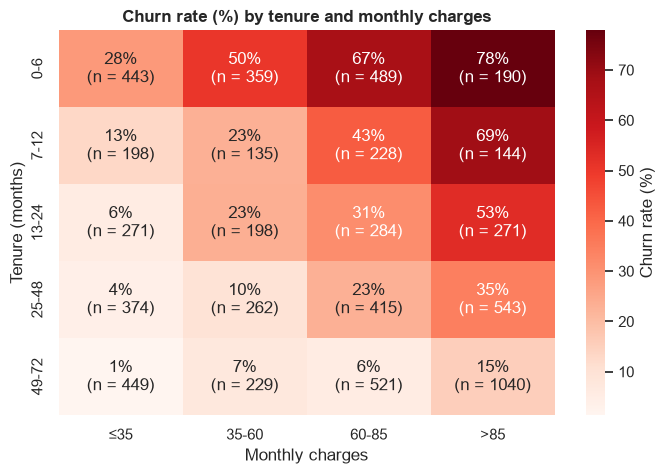

In [32]:
# Bins for the heatmap
tenure_group = pd.cut(df['tenure'], bins=[-1, 6, 12, 24, 48, 72],
                      labels=['0-6', '7-12', '13-24', '25-48', '49-72'])
charges_group = pd.cut(df['MonthlyCharges'], bins=[0, 35, 60, 85, 120],
                       labels=['≤35', '35-60', '60-85', '>85'])

#  Churn rate (%) for each tenure x charges combination
pct = ((df['Churn'] == 'Yes') * 100).groupby([tenure_group, charges_group], observed=True).mean().unstack()
n = df.groupby([tenure_group, charges_group], observed=True).size().unstack()
labels = pct.round(0).astype(int).astype(str) + '%\n(n = ' + n.astype(str) + ')'

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pct, annot=labels, fmt='', cmap='Reds', cbar_kws={'label': 'Churn rate (%)'}, ax=ax)
ax.set_title('Churn rate (%) by tenure and monthly charges', fontsize=12, weight='bold')
ax.set_xlabel('Monthly charges'), ax.set_ylabel('Tenure (months)')
plt.show()

In this case we can see clearly that clients with a high tenure are not affected by the monthly charges as much as clients with low tenure. This could give us an approach to retaining clients.

### 5.5 Key findings

Here are the key findings from the EDA:
* Base churn rate is 26.54%
* Month-to-month contracts churn at 42.71% vs 2.83% for two year contracts
* Fiber optic clients churn at 41.89% vs 18.96% for DSL.
* Churn concentrates in the first months. Clients with 0-6 months of tenure and monthly charges above $85 churn at 78% (n = 190).
* Senior citizens churn at 41.68% vs 23.61%, partly explained by their contract and internet service profile.
* `gender` shows no differences. `PhoneService` shows none overall, but it only exists within DSL (see 5.3.4).
* `TotalCharges` is nearly redundant with `tenure` * `MonthlyCharges`. Keep in mind for the model.

## 6. Data preparation for modeling

### 6.1 Target and features

The target is `Churn`, encoded as 1 (churned) and 0 (stayed). `customerID` is only an identifier and carries no predictive information, so it is dropped from the features.

In [33]:
# Target: 1 = churned, 0 = stayed
y = (df['Churn'] == 'Yes').astype(int)

# Features: everything except the identifier and the target
X = df.drop(columns=['customerID', 'Churn'])

print(f'Features: {X.shape[1]} | Observations: {X.shape[0]} | Churn rate: {y.mean():.2%}')

Features: 19 | Observations: 7043 | Churn rate: 26.54%


### 6.2 Handling TotalCharges

In the EDA we saw that `TotalCharges` is almost `tenure` × `MonthlyCharges`. To measure how redundant it is, we use the Variance Inflation Factor (VIF). Values above ~5 are usually a sign of problematic multicollinearity.

In [34]:
# VIF of the numeric variables, with and without TotalCharges
def vif_table(cols):
    exog = sm.add_constant(df[cols])
    return pd.Series(
        [variance_inflation_factor(exog.values, i) for i in range(1, exog.shape[1])],
        index=cols
    ).round(2)

display(pd.concat({
    'With TotalCharges': vif_table(['tenure', 'MonthlyCharges', 'TotalCharges']),
    'Without TotalCharges': vif_table(['tenure', 'MonthlyCharges'])
}, axis=1))

# Drop TotalCharges from the features
X = X.drop(columns=['TotalCharges'])

,With TotalCharges,Without TotalCharges
tenure,5.84,1.07
MonthlyCharges,3.22,1.07
TotalCharges,9.51,NaN


`TotalCharges` has a VIF of 9.51 and pushes the VIF of `tenure` to 5.84. Without it, both variables drop to 1.07. Since it adds almost no information beyond `tenure` and `MonthlyCharges`, and would make the coefficients of a linear model unstable, we drop it.

### 6.3 Encoding categorical variables

* **Redundant categories:** *No internet service* and *No phone service* repeat information already contained in `InternetService` and `PhoneService`, so they are merged into *No*. Otherwise they would create perfectly collinear dummies.
* **Binary variables** (Yes/No) are mapped to 1/0. `gender` becomes `Male` (1 = Male).
* **Multi-category variables** (`InternetService`, `Contract`, `PaymentMethod`) are one-hot encoded. The reference categories (dropped) are *DSL*, *Month-to-month* and *Bank transfer (automatic)*, so the coefficients of the model are interpreted relative to them.

In [35]:
# Merge redundant categories in the add-on services
service_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
X[service_cols] = X[service_cols].replace({'No internet service': 'No', 'No phone service': 'No'})

# Binary variables to 0/1
binary_cols = ['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling'] + service_cols
X[binary_cols] = X[binary_cols].apply(lambda s: (s == 'Yes').astype(int))
X['gender'] = (X['gender'] == 'Male').astype(int)
X = X.rename(columns={'gender': 'Male'})

# Dropping the reference categories explicitly
X = pd.get_dummies(X, columns=['InternetService', 'Contract', 'PaymentMethod'], dtype=int)
reference = ['InternetService_DSL', 'Contract_Month-to-month', 'PaymentMethod_Bank transfer (automatic)']
X = X.drop(columns=reference)

# Checks everything numeric and no missing values
assert X.select_dtypes(exclude='number').empty
assert not X.isna().any().any()

print(f'Shape: {X.shape}')
display(X.head())

Shape: (7043, 22)


,Male,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,StreamingMovies,PaperlessBilling,MonthlyCharges,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,0,1,29.85,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,0,0,56.95,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,0,1,53.85,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,0,0,42.30,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,1,70.70,1,0,0,0,0,1,0


### 6.4 Train/test split

The data is split into 80% for training and 20% for testing. The split is stratified by `Churn`, so both sets keep the same churn rate (~26.5%), which matters because of the class imbalance. A fixed `random_state` makes the results reproducible.

Scaling of the numeric variables (`tenure`, `MonthlyCharges`) is not done here: for the models that need it, it will be done inside a pipeline fitted only on the training data, to avoid leaking information from the test set.

In [36]:
# 80-20 stratified split
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    'rows': [len(y_train), len(y_test)],
    'churn_rate_%': [y_train.mean() * 100, y_test.mean() * 100]
}, index=['train', 'test']).round(2)
display(split_summary)

# Checks
assert len(X_train) + len(X_test) == len(X)
assert abs(y_train.mean() - y_test.mean()) < 0.005

# Final feature set: MonthlyCharges is excluded from the model (see 7.3 and 7.5),
# but it is kept aside to compute the value of each client in section 8
X_train_f = X_train.drop(columns='MonthlyCharges')
X_test_f = X_test.drop(columns='MonthlyCharges')

,rows,churn_rate_%
train,5634,26.54
test,1409,26.54


## 7. Modeling

We train and compare four models (plus a logistic regression variant with `MonthlyCharges`): a logistic regression with linear `tenure`, the same with a spline on `tenure`, Random Forest and HistGradientBoosting.

### 7.1 Evaluation approach

Since only ~26.5% of clients churn, **accuracy is misleading**: a model that predicts "no churn" for everyone already reaches ~73.5%. We use:

* **ROC-AUC:** how well the model ranks churners above non-churners, independent of any threshold.
* **PR-AUC (average precision):** more informative than ROC-AUC when the positive class is a minority. A random model scores ~0.27 (the churn rate).
* **Brier score:** mean squared error of the predicted probabilities (lower is better). It matters because section 8 uses the probabilities directly to make decisions. A model that always predicts the base rate scores 0.195.

The models are trained without class weights, which would distort the predicted probabilities. The calibration of the final model is checked in 8.2. Recall and precision are not used to compare models, because they depend on a threshold, which is a business decision (section 8). A dummy classifier that always predicts “no churn” is our reference point.

In [37]:
def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        'ROC-AUC': roc_auc_score(y, proba),
        'Recall': recall_score(y, pred),
        'Precision': precision_score(y, pred, zero_division=0),
        'F1': f1_score(y, pred, zero_division=0),
        'Accuracy': accuracy_score(y, pred),
    }

# Reference: always predicts the majority class (no churn)
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
display(pd.DataFrame({'Dummy classifier': evaluate(dummy, X_test, y_test)}).T.round(3))

,ROC-AUC,Recall,Precision,F1,Accuracy
Dummy classifier,0.5,0.0,0.0,0.0,0.735


### 7.2 Logistic Regression and spline on tenure (final model)

The model is a logistic regression without `MonthlyCharges` (see 7.3 and 7.5), with `tenure` scaled inside a pipeline so the scaler is fitted only on the training data of each fold. We also keep a version with `MonthlyCharges` to show that excluding it costs nothing. The final model adds a spline on tenure (7.5.1) and all features are standardized after the spline.

In [38]:
def make_logreg(numeric_cols):
    preprocess = ColumnTransformer([('scale', StandardScaler(), numeric_cols)], remainder='passthrough')
    return Pipeline([('preprocess', preprocess),
                     ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

log_reg_full = make_logreg(['tenure', 'MonthlyCharges'])   # for comparison only
log_reg = make_logreg(['tenure'])                          # linear tenure (baseline)

def make_logreg_spline(n_knots=5):
    """Logistic regression with a smooth non-linear effect of tenure (cubic spline)."""
    preprocess = ColumnTransformer(
        [('tenure_spline', SplineTransformer(n_knots=n_knots, degree=3), ['tenure'])],
        remainder='passthrough')
    return Pipeline([('preprocess', preprocess),
                     ('scale', StandardScaler()),
                     ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))])    # final model

### 7.3 Interpreting the logistic regression

To read the coefficients we use `statsmodels`, which gives confidence intervals and p-values. First, we check multicollinearity on all features. `MonthlyCharges` is almost a linear combination of the contracted services (the price depends on them), which makes the coefficients unstable. For interpretation, we exclude it as this does not affect predictive performance (see 7.5). The logistic regression fitted with `statsmodels` uses a linear effect of `tenure` and is used only to interpret the other variables. The final model (7.5.1) uses a spline on `tenure`, so the odds ratio of `tenure` below is a linear approximation.

In [39]:
def vif_series(data):
    exog = sm.add_constant(data)
    return pd.Series([variance_inflation_factor(exog.values, i) for i in range(1, exog.shape[1])],
                     index=data.columns)

display(pd.concat({
    'All features': vif_series(X_train),
    'Without MonthlyCharges': vif_series(X_train_f)
}, axis=1).sort_values('All features', ascending=False).head(6).round(1))

,All features,Without MonthlyCharges
MonthlyCharges,860.1,NaN
InternetService_Fiber optic,147.8,2.0
InternetService_No,103.0,2.7
PhoneService,35.3,1.4
StreamingTV,24.0,1.6
StreamingMovies,24.0,1.6


,odds_ratio,ci_low,ci_high,p_value
InternetService_Fiber optic,2.504,2.046,3.065,0.000
PaymentMethod_Electronic check,1.470,1.194,1.810,0.000
PaperlessBilling,1.447,1.229,1.704,0.000
MultipleLines,1.386,1.165,1.647,0.000
StreamingTV,1.326,1.113,1.579,0.002
StreamingMovies,1.325,1.112,1.579,0.002
SeniorCitizen,1.153,0.958,1.390,0.133
PaymentMethod_Mailed check,1.117,0.869,1.436,0.386
Male,1.024,0.888,1.181,0.746
Partner,1.023,0.863,1.213,0.789


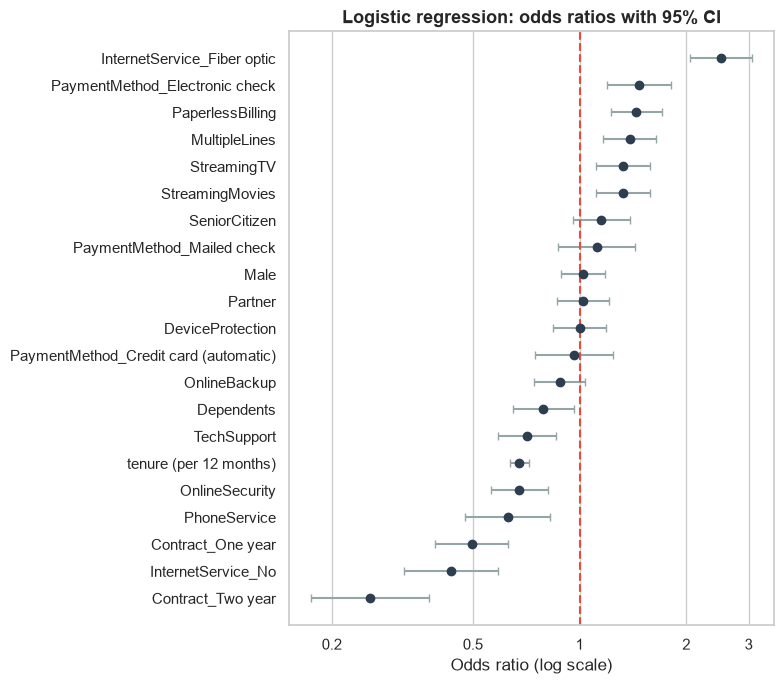

In [40]:
logit = sm.Logit(y_train, sm.add_constant(X_train_f)).fit(disp=False)
ci = logit.conf_int()

odds = (pd.DataFrame({
    'odds_ratio': np.exp(logit.params),
    'ci_low': np.exp(ci[0]),
    'ci_high': np.exp(ci[1]),
    'p_value': logit.pvalues
}).drop(index='const').sort_values('odds_ratio', ascending=False).round(3))
display(odds)

cols = ['odds_ratio', 'ci_low', 'ci_high']
odds.loc['tenure', cols] = (odds.loc['tenure', cols] ** 12).round(3)
odds = odds.rename(index={'tenure': 'tenure (per 12 months)'}).sort_values('odds_ratio', ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
pos = np.arange(len(odds))
ax.errorbar(odds['odds_ratio'], pos,
            xerr=[odds['odds_ratio'] - odds['ci_low'], odds['ci_high'] - odds['odds_ratio']],
            fmt='o', color='#2C3E50', ecolor='#95A5A6', capsize=3)
ax.axvline(1, color='#E74C3C', linestyle='--')
ax.set_yticks(pos)
ax.set_yticklabels(odds.index)
ax.invert_yaxis()
ax.set_xscale('log')
ax.set_xticks([0.2, 0.5, 1, 2, 3])
ax.set_xticklabels(['0.2', '0.5', '1', '2', '3'])
ax.minorticks_off()
ax.set_xlabel('Odds ratio (log scale)')
ax.set_title('Logistic regression: odds ratios with 95% CI', fontsize=13, weight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout()
fig.savefig('images/odds_ratios.png', dpi=150, bbox_inches='tight')
plt.show()

An odds ratio above 1 means higher odds of churn, and below 1 lower odds, with the other variables held constant and relative to the reference category (*DSL*, *Month-to-month*, *Bank transfer (automatic)*). If the interval includes 1, there is no evidence of an independent effect. Also, because `MonthlyCharges` was excluded to avoid multicollinearity with the service indicators, the odds ratios for services like Fiber optic (2.50) and Streaming (~1.33) capture both the service experience and its associated price tier.

* **Contract** is the strongest factor: *Two year* (0.26) and *One year* (0.50) lower the odds of churn considerably compared to *Month-to-month*.
* **Fiber optic** has 2.5 times the odds of churn of DSL, even after controlling for contract and the rest. This is not only a contract effect.
* **Tenure:** under the linear approximation each additional month lowers the odds by ~3% (0.968). The real effect is not linear: observed churn falls from 59% in the first three months to 30% at 6–12 months and 6% after five years (7.5.1).
* **Payment method:** *Electronic check* increases the odds (1.47), but *Mailed check* (1.12) is not significant and *Credit card* is the same as *Bank transfer*. Our hypothesis was only partially right: the difference is about electronic check, not about manual vs automatic.
* **Add-on services:** *TechSupport* (0.71) and *OnlineSecurity* (0.68) reduce the odds of churn, but *StreamingTV* and *StreamingMovies* increase them (~1.33), and *DeviceProtection* and *OnlineBackup* show no clear effect. "More add-ons, less churn" only holds for support and security.
* **`SeniorCitizen`, `Partner` and `gender` show no statistically significant independent effect:** Once the other variables are controlled, the ~18pp gap of senior citizens seen in the EDA goes with differences in contract and internet service profile (5.3.1) but is no longer statistically significant, and the ~7-9pp gap of `Partner` left in 5.2.4 after controlling for `Dependents` is also no longer significant (OR 1.02, p = 0.79).

In [41]:
# Robustness: odds ratios of the other variables when tenure enters as a spline (as in the final model)
sp_basis = SplineTransformer(n_knots=5, degree=3, include_bias=False).fit(X_train_f[['tenure']])
B = pd.DataFrame(sp_basis.transform(X_train_f[['tenure']]), index=X_train_f.index,
                 columns=[f'tenure_spline_{i}' for i in range(sp_basis.n_features_out_)])
logit_sp = sm.Logit(y_train, sm.add_constant(pd.concat([B, X_train_f.drop(columns='tenure')], axis=1))).fit(disp=False)

others = [c for c in X_train_f.columns if c != 'tenure']
robust = pd.DataFrame({'OR_linear_tenure': np.exp(logit.params[others]),
                       'OR_spline_tenure': np.exp(logit_sp.params[others]),
                       'p_linear': logit.pvalues[others], 'p_spline': logit_sp.pvalues[others]})
robust['ratio'] = robust['OR_spline_tenure'] / robust['OR_linear_tenure']
display(robust.sort_values('ratio').round(3))

,OR_linear_tenure,OR_spline_tenure,p_linear,p_spline,ratio
Contract_Two year,0.256,0.208,0.000,0.000,0.811
PaymentMethod_Mailed check,1.117,1.001,0.386,0.994,0.896
PhoneService,0.627,0.596,0.001,0.000,0.950
PaymentMethod_Electronic check,1.470,1.406,0.000,0.001,0.957
Contract_One year,0.496,0.481,0.000,0.000,0.969
OnlineBackup,0.878,0.867,0.128,0.098,0.988
InternetService_No,0.434,0.432,0.000,0.000,0.995
Male,1.024,1.024,0.746,0.743,1.000
SeniorCitizen,1.153,1.166,0.133,0.106,1.011
PaymentMethod_Credit card (automatic),0.966,0.983,0.789,0.895,1.018


Robustness to the spline. The final model uses a spline on `tenure`, while this `statsmodels` model uses a linear term. Refitting it with the spline basis changes the odds ratios of the other variables by at most ~7%, except the two-year contract (0.26 → 0.21) and mailed check (1.12 → 1.00, not significant in either model). No variable changes statistical significance at the 5% level (`Dependents` moves from p = 0.02 to p = 0.05, borderline), so the conclusions do not change.

#### 7.3.1 Hypotheses scorecard

Summary of the hypotheses from section 1.2, what the EDA showed, and what remains once the other variables are controlled (odds ratios from the model above).

| Variable | Expected | Bivariate (EDA) | Multivariate (7.3) | Verdict |
|---|---|---|---|---|
| `gender` | No effect | 26.9% vs 26.2% | OR 1.02 (p = 0.75) | Confirmed |
| `Partner` | No effect | 19.7% with vs 33.0% without | OR 1.02 (p = 0.79) | Apparent effect in the EDA (13 pp), but no statistically significant independent effect once controlled |
| `PaperlessBilling` | No effect | 33.6% vs 16.3% | OR 1.45 (95% CI 1.23-1.70) | Refuted, the effect persists |
| `SeniorCitizen` | Lower churn | 41.7% vs 23.6% (higher, not lower) | OR 1.15 (p = 0.13) | Refuted (higher, not lower). The gap goes with differences in contract and internet profile (5.3.1) and is not statistically significant in the multivariate model |
| `Dependents` | Lower churn | 15.5% vs 31.3% | OR 0.79 (p = 0.02) | Confirmed, smaller effect |
| `tenure` | Longer tenure, lower churn | r = -0.35 | OR 0.968 per month (about 0.68 per 12 months) | Confirmed, the effect is non-linear |
| `Contract` | Month-to-month churns more | 42.7% / 11.3% / 2.8% (month-to-month / one year / two year) | OR 0.50 (one year), 0.26 (two year) | Confirmed, the strongest factor |
| `PaymentMethod` | Automatic lower, manual higher | Electronic check 45.3%, mailed check 19.1%, bank transfer 16.7%, credit card 15.2% | Electronic check OR 1.47, mailed check 1.12 (p = 0.39) | Partly, only electronic check stands out |
| `MonthlyCharges` | Higher charge, higher churn | r = 0.19 | Not estimated (collinear with the services, VIF 860) | Partly, the effect concentrates in short tenures (5.4.3) |
| `TotalCharges` | Higher total, lower churn | r = -0.20 | Dropped (redundant with tenure × MonthlyCharges) | Confirmed, but redundant |
| Add-on services | More add-ons, lower churn | 52.2% with none to 5.3% with all six | `TechSupport` 0.71 and `OnlineSecurity` 0.68 lower, streaming ~1.33 higher, backup and device protection no clear effect | Partly, holds only for support and security |
| `InternetService` (not hypothesized) | None | Fiber optic 41.9% vs DSL 19.0% | Fiber optic OR 2.50 (95% CI 2.05-3.07) | Unexpected, the largest single effect after contract |
| `PhoneService` (not hypothesized) | None | 24.9% vs 26.7% overall, within DSL 24.9% vs 16.6% | OR 0.63 (95% CI 0.48 to 0.83) | Unexpected, only exists within DSL, do not interpret alone |
| `MultipleLines` (not hypothesized) | None | 28.6% vs 25.0% | OR 1.39 (95% CI 1.17 to 1.65) | Unexpected, direction reverses vs. within-type rates |

### 7.4 Tree-based models

Random Forest and HistGradientBoosting can capture non-linear effects and interactions (like the tenure × monthly charges pattern seen in the EDA) without extra feature engineering. They use moderate hyperparameters to limit overfitting.

In [42]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)
gb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=150, max_depth=3, random_state=RANDOM_STATE)

# (model, train features, test features)
models = {
    'Logistic Regression (linear tenure)': (log_reg, X_train_f, X_test_f),
    'Logistic Regression (spline tenure)': (make_logreg_spline(), X_train_f, X_test_f),
    'Logistic Regression (+ MonthlyCharges)': (log_reg_full, X_train, X_test),
    'Random Forest': (rf, X_train, X_test),
    'HistGradientBoosting': (gb, X_train, X_test),
}

### 7.5 Model comparison with cross-validation

We compare the models with 5-fold stratified cross-validation on the training set. The test set is not used here.

In [43]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, (model, Xtr, _) in models.items():
    s = cross_validate(model, Xtr, y_train, cv=cv,
                       scoring=['roc_auc', 'average_precision', 'neg_brier_score'])
    cv_results[name] = {'ROC-AUC': s['test_roc_auc'].mean(),
                        'ROC-AUC std': s['test_roc_auc'].std(),
                        'PR-AUC': s['test_average_precision'].mean(),
                        'Brier': -s['test_neg_brier_score'].mean()}

display(pd.DataFrame(cv_results).T.round(3))

,ROC-AUC,ROC-AUC std,PR-AUC,Brier
Logistic Regression (linear tenure),0.845,0.012,0.659,0.135
Logistic Regression (spline tenure),0.849,0.012,0.671,0.133
Logistic Regression (+ MonthlyCharges),0.845,0.012,0.660,0.135
Random Forest,0.845,0.010,0.654,0.136
HistGradientBoosting,0.849,0.011,0.669,0.134


The logistic regression with a linear effect of tenure is slightly behind in PR-AUC (0.659 vs 0.669 for HistGradientBoosting). Allowing a non-linear effect of tenure closes the gap (ROC-AUC 0.849, PR-AUC 0.671), so the four models are equivalent: ROC-AUC 0.845–0.849 (std ~0.01) and PR-AUC 0.65–0.67. Adding MonthlyCharges to the logistic regression changes nothing, so excluding it for interpretation costs no predictive performance. All models have a Brier score of ~0.135, well below the 0.195 of a model that always predicts the base rate.

#### 7.5.1 Non-linear effect of tenure
Churn falls quickly in the first months (59% in the first three months of the test set, 30% at 6–12 months, 6% beyond five years), which a straight line in the log-odds cannot follow. A cubic spline on tenure allows a smooth non-linear effect while keeping the model a logistic regression. The number of knots does not matter (3 to 8 knots give a PR-AUC of 0.670–0.671). By tenure bin, the mean absolute gap between predicted and observed churn falls from 4.2 to 2.0 pp.

In [44]:
candidates = {'Logistic Regression (linear tenure)': log_reg,
              'Logistic Regression (spline tenure)': make_logreg_spline()}

# Sensitivity to the number of knots (CV only)
knots_rows = {}
for k in [3, 4, 5, 6, 8]:
    s = cross_validate(make_logreg_spline(k), X_train_f, y_train, cv=cv,
                       scoring=['roc_auc', 'average_precision'])
    knots_rows[f'n_knots={k}'] = {'ROC-AUC': s['test_roc_auc'].mean(), 'PR-AUC': s['test_average_precision'].mean()}
display(pd.DataFrame(knots_rows).T.round(3))

,ROC-AUC,PR-AUC
n_knots=3,0.849,0.670
n_knots=4,0.849,0.670
n_knots=5,0.849,0.671
n_knots=6,0.850,0.671
n_knots=8,0.850,0.671


,ROC-AUC,PR-AUC,Brier
Logistic Regression (linear tenure),0.839,0.630,0.139
Logistic Regression (spline tenure),0.848,0.665,0.135


,clients,observed,Logistic Regression (linear tenure),Logistic Regression (spline tenure)
tenure,,,,
0–3,230,0.591,0.468,0.556
4–6,81,0.457,0.465,0.464
7–12,138,0.304,0.392,0.341
13–24,206,0.291,0.363,0.306
25–36,163,0.245,0.262,0.220
37–48,141,0.170,0.178,0.168
49–60,174,0.109,0.120,0.145
61–72,276,0.058,0.052,0.065


Mean absolute error by tenure bin (pp): {'Logistic Regression (linear tenure)': np.float64(4.2), 'Logistic Regression (spline tenure)': np.float64(2.0)}


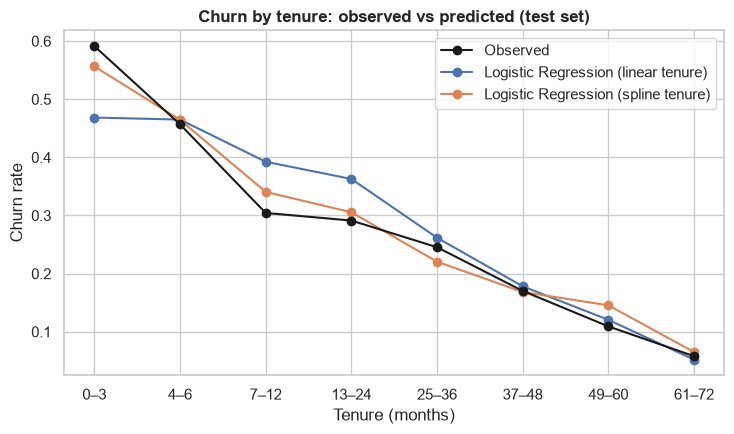

In [45]:
fitted = {n: m.fit(X_train_f, y_train) for n, m in candidates.items()}
rows = {}
for n, m in fitted.items():
    p = m.predict_proba(X_test_f)[:, 1]
    rows[n] = {'ROC-AUC': roc_auc_score(y_test, p), 'PR-AUC': average_precision_score(y_test, p),
               'Brier': brier_score_loss(y_test, p)}
display(pd.DataFrame(rows).T.round(3))

# Predicted vs observed churn by tenure bin
labels = ['0–3', '4–6', '7–12', '13–24', '25–36', '37–48', '49–60', '61–72']
bins = pd.cut(X_test_f['tenure'], [-1, 3, 6, 12, 24, 36, 48, 60, 72], labels=labels)
cmp = pd.DataFrame({'clients': y_test.groupby(bins, observed=True).size(),
                    'observed': y_test.groupby(bins, observed=True).mean()})
for n, m in fitted.items():
    cmp[n] = pd.Series(m.predict_proba(X_test_f)[:, 1], index=X_test_f.index).groupby(bins, observed=True).mean()
display(cmp.round(3))
print('Mean absolute error by tenure bin (pp):',
      {n: round((cmp[n] - cmp['observed']).abs().mean() * 100, 1) for n in fitted})

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(labels, cmp['observed'], 'ko-', label='Observed', zorder=3)
for n in fitted:
    ax.plot(labels, cmp[n], marker='o', label=n)
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('Churn rate')
ax.set_title('Churn by tenure: observed vs predicted (test set)', fontsize=12, weight='bold')
ax.legend()
plt.tight_layout()
fig.savefig('images/tenure_effect.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.6 Final evaluation on the test set

Each model is fitted on the full training set and evaluated once on the test set.

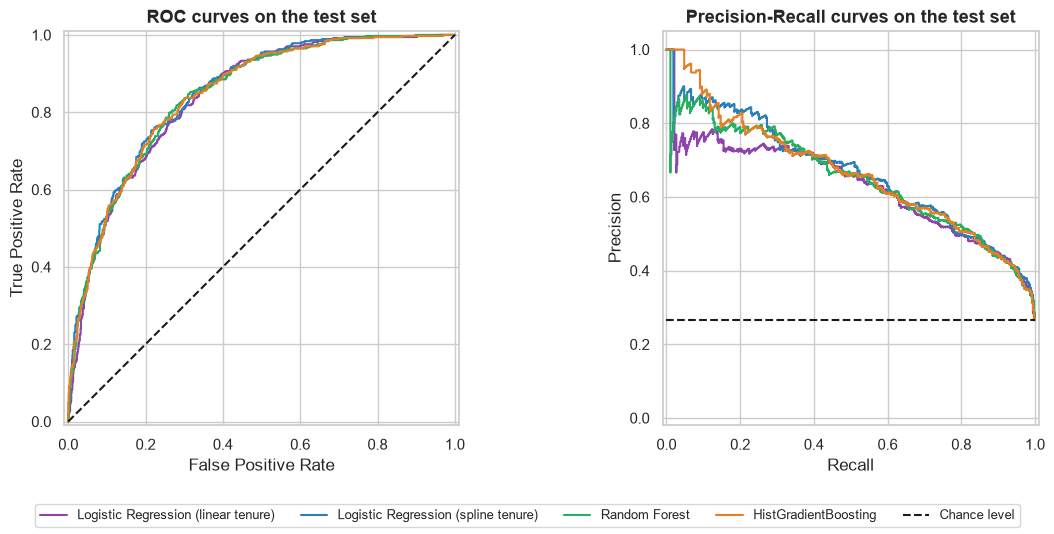

,ROC-AUC,PR-AUC,Brier
Logistic Regression (linear tenure),0.839,0.630,0.139
Logistic Regression (spline tenure),0.848,0.665,0.135
Random Forest,0.843,0.650,0.136
HistGradientBoosting,0.844,0.664,0.136


Brier of a model that always predicts the base rate: 0.195


In [46]:
# The variant with MonthlyCharges is left out of the plot (its numbers are in the CV table)
plot_models = {k: v for k, v in models.items() if k != 'Logistic Regression (+ MonthlyCharges)'}
curve_colors = ['#8E44AD', '#2980B9', '#27AE60', '#E67E22']   # purple, blue, green, orange

test_results = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax in axes:
    ax.set_prop_cycle(color=curve_colors)

for i, (name, (model, Xtr, Xte)) in enumerate(plot_models.items()):
    model.fit(Xtr, y_train)
    proba = model.predict_proba(Xte)[:, 1]
    test_results[name] = {
        'ROC-AUC': roc_auc_score(y_test, proba),
        'PR-AUC': average_precision_score(y_test, proba),
        'Brier': brier_score_loss(y_test, proba)
    }
    is_last = (i == len(plot_models) - 1)
    RocCurveDisplay.from_predictions(
        y_test, proba, name=name, ax=axes[0], plot_chance_level=is_last
    )
    PrecisionRecallDisplay.from_predictions(
        y_test, proba, name=name, ax=axes[1], plot_chance_level=is_last
    )

axes[0].set_title('ROC curves on the test set', fontsize=13, weight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')

axes[1].set_title('Precision-Recall curves on the test set', fontsize=13, weight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_ylim(-0.02, 1.05)

# One shared legend (without the per-plot metric, which is in the table below)
handles, labels = axes[0].get_legend_handles_labels()
labels = [re.sub(r'\s*\((AUC|AP) = [\d.]+\)', '', l) for l in labels]
for ax in axes:
    if ax.get_legend() is not None:
        ax.get_legend().remove()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=True, fontsize=9.5)

plt.tight_layout(rect=(0, 0.07, 1, 0.98))
fig.savefig('images/roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

display(pd.DataFrame(test_results).T.round(3))
base_brier = brier_score_loss(y_test, np.full(len(y_test), y_train.mean()))
print(f'Brier of a model that always predicts the base rate: {base_brier:.3f}')

On the test set the logistic regression with spline `tenure`, Random Forest and HistGradientBoosting are very close (ROC-AUC 0.843–0.848, PR-AUC 0.650–0.665, Brier 0.135–0.136). The logistic regression with linear `tenure` is slightly behind (PR-AUC 0.630), which the spline removes. We keep the logistic regression with spline `tenure`: it matches the tree-based models and stays simple.

## 8. Evaluation and Conclusions

In this section we choose the final model, decide how to turn its probabilities into decisions, evaluate it on the test set, and translate the results into recommendations.

### 8.1 Final model

The final model is the logistic regression with a spline on `tenure` (7.5.1), no `MonthlyCharges` and no class weights. Its probabilities are consistent with observed churn rates (8.2), so they can be used directly to make decisions. The tree-based models give no additional gain.

In [47]:
final_model = make_logreg_spline().fit(X_train_f, y_train)
test_proba = final_model.predict_proba(X_test_f)[:, 1]

### 8.2 Calibration and decision rule

Since the model is trained without class weights, its probabilities can be read as probabilities. On the test set, the calibration intercept is −0.04 (95% CI −0.20 to 0.12) and the slope is 0.97 (0.85 to 1.09), where 0 and 1 mean perfect calibration. The largest gap between predicted and observed churn is ~8pp in one mid-range decile (predicted 46%, observed 38%), at the limit of the sampling error of a decile of ~141 clients (about ±8pp).

Instead of searching for a probability threshold, we use the expected value of contacting each client: `EV = p × success rate × client value − offer cost`. A client is contacted only if EV > 0. The cutoff adapts to the client: a client paying 70 USD/month is contacted from a churn probability of ~0.20, while one paying 20 USD/month needs ~0.69.

The dataset has no cost information, so the assumptions are illustrative: a 30% success rate, 50 USD per offer, and a client value of 12 months of their monthly charge (revenue, not margin). They are variables so they can be changed.

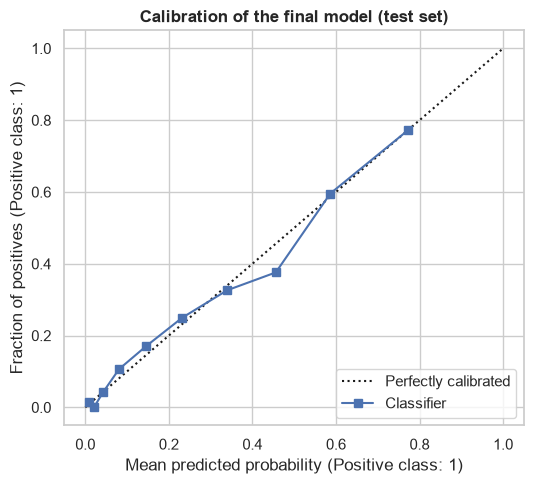

offer_cost (USD),25,50,100
success_rate,,,
0.1,36.3,19.7,0.6
0.2,50.0,36.3,19.7
0.3,56.8,44.0,30.9
0.4,61.2,50.0,36.3


,estimate,ci_low,ci_high
const,-0.042,-0.199,0.116
slope,0.969,0.852,1.085


In [48]:
fig, ax = plt.subplots(figsize=(5.5, 5))
CalibrationDisplay.from_predictions(y_test, test_proba, n_bins=10, strategy='quantile', ax=ax)
ax.set_title('Calibration of the final model (test set)', fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

# Illustrative assumptions (not in the dataset)
success_rate = 0.30                       # share of contacted churners that the offer retains
offer_cost = 50                           # USD per contacted client
client_value = X_test['MonthlyCharges'] * 12   # 12 months of revenue (not margin)

# Contact a client only if the expected value of the offer is positive
expected_value = test_proba * success_rate * client_value - offer_cost
contact_ev = (expected_value > 0).to_numpy()

# Sensitivity: share of clients contacted under different assumptions
sens_rows = []
for sr in [0.1, 0.2, 0.3, 0.4]:
    for oc in [25, 50, 100]:
        c = ((test_proba * sr * client_value - oc) > 0).to_numpy()
        sens_rows.append({'success_rate': sr, 'offer_cost': oc, 'contacted_%': c.mean() * 100})

display(pd.DataFrame(sens_rows)
        .pivot(index='success_rate', columns='offer_cost', values='contacted_%')
        .round(1).rename_axis(columns='offer_cost (USD)'))

# Calibration intercept and slope (perfect calibration: 0 and 1)
calib_X = sm.add_constant(pd.Series(np.log(test_proba / (1 - test_proba)), index=y_test.index, name='slope'))
calib = sm.Logit(y_test, calib_X).fit(disp=False)
display(pd.concat([calib.params, calib.conf_int()], axis=1).set_axis(['estimate', 'ci_low', 'ci_high'], axis=1).round(3))

The share of clients contacted depends heavily on the assumptions: from ~20% to 61% in most scenarios, and practically nobody (0.6%) if offers are expensive and rarely work (10% success, 100 USD).

### 8.3 Performance on the test set

,contacted_%,recall,precision,net_benefit_usd
strategy,,,,
Contact everyone,100.00,1.00,0.27,27523.64
Probability >= 0.5,21.29,0.53,0.66,39629.10
Top 20% by risk,20.01,0.52,0.68,39363.06
Top 44% by risk,44.00,0.82,0.49,51198.08
Expected value > 0,44.00,0.79,0.48,52882.16


EV rule minus Top 44%: 1,697 USD (95% bootstrap interval -434 to 4,080)


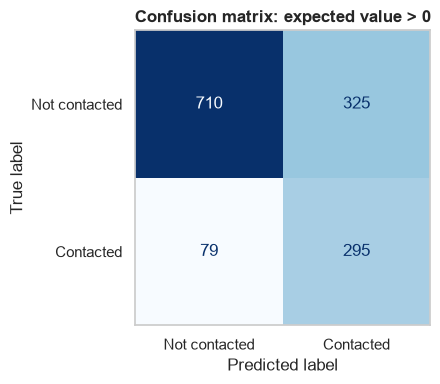

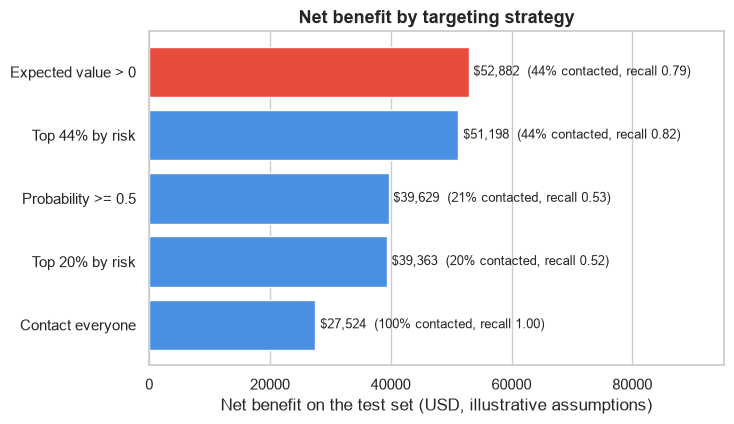

In [49]:
yt = y_test.to_numpy()

def strategy_summary(contact, name):
    contact = np.asarray(contact, dtype=bool)
    tp = (contact & (yt == 1)).sum()
    return {'strategy': name,
            'contacted_%': contact.mean() * 100,
            'recall': tp / yt.sum(),
            'precision': tp / max(contact.sum(), 1),
            'net_benefit_usd': (contact * (yt * success_rate * client_value.to_numpy() - offer_cost)).sum()}

# Same number of clients as the EV rule, but ranked only by probability
share_ev = contact_ev.mean()
top_same = test_proba >= np.quantile(test_proba, 1 - share_ev)

strategies = pd.DataFrame([
    strategy_summary(np.ones(len(yt)), 'Contact everyone'),
    strategy_summary(test_proba >= 0.5, 'Probability >= 0.5'),
    strategy_summary(test_proba >= np.quantile(test_proba, 0.80), 'Top 20% by risk'),
    strategy_summary(top_same, f'Top {share_ev:.0%} by risk'),
    strategy_summary(contact_ev, 'Expected value > 0'),
]).set_index('strategy')
display(strategies.round(2))

# Is the EV rule really better than the simple ranking? Bootstrap of the net benefit difference
def net_benefit(contact, idx):
    return (contact[idx] * (yt[idx] * success_rate * client_value.to_numpy()[idx] - offer_cost)).sum()

rng = np.random.default_rng(RANDOM_STATE)
diffs = np.array([net_benefit(contact_ev, idx) - net_benefit(top_same, idx)
                  for idx in (rng.integers(0, len(yt), len(yt)) for _ in range(2000))])
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'EV rule minus Top {share_ev:.0%}: {diffs.mean():,.0f} USD (95% bootstrap interval {lo:,.0f} to {hi:,.0f})')

cm = confusion_matrix(y_test, contact_ev.astype(int))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Not contacted', 'Contacted']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion matrix: expected value > 0', fontsize=12, weight='bold')
ax.grid(False)
plt.tight_layout()
plt.show()

# Figure for the README
plot_df = strategies.sort_values('net_benefit_usd')
colors = ['#E74C3C' if s == 'Expected value > 0' else '#4A90E2' for s in plot_df.index]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.barh(plot_df.index, plot_df['net_benefit_usd'], color=colors)
for pos, (_, r) in enumerate(plot_df.iterrows()):
    ax.text(r['net_benefit_usd'] + 800, pos,
            f"${r['net_benefit_usd']:,.0f}  ({r['contacted_%']:.0f}% contacted, recall {r['recall']:.2f})",
            va='center', fontsize=9)
ax.set_xlim(0, plot_df['net_benefit_usd'].max() * 1.8)
ax.set_xlabel('Net benefit on the test set (USD, illustrative assumptions)')
ax.set_title('Net benefit by targeting strategy', fontsize=13, weight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout()
fig.savefig('images/net_benefit_by_strategy.png', dpi=150, bbox_inches='tight')
plt.show()

The decision rule has no parameter tuned on the data (only the assumed costs), so it can be evaluated directly on the test set using the real outcomes: a contacted churner yields success rate × value − cost, and a contacted client who would have stayed costs the offer.

| Strategy | Contacted | Recall | Precision | Net benefit (USD) |
|---|---|---|---|---|
| Contact everyone | 100% | 1.00 | 0.27 | \$27,524 |
| Probability ≥ 0.5 | 21% | 0.53 | 0.66 | \$39,629 |
| Top 20% by risk | 20% | 0.52 | 0.68 | \$39,363 |
| Top 44% by risk | 44% | 0.82 | 0.49 | \$51,198 |
| **Expected value > 0** | **44%** | **0.79** | **0.48** | **\$52,882** |

The expected value rule catches 295 of the 374 churners (79%) by contacting 44% of the clients (620), with 48% precision (325 contacted clients would have stayed). Ranking by probability and contacting the same 44% gives a net benefit 1,697 USD lower (95% bootstrap interval −434 to 4,080), so in this test set the difference is small and its interval includes zero. Most of the gain over the fixed rules comes from choosing how many clients to contact.

In [50]:
res = []
for seed in range(30):
    a, b, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    m = make_logreg_spline().fit(a.drop(columns='MonthlyCharges'), ya)
    pp = m.predict_proba(b.drop(columns='MonthlyCharges'))[:, 1]
    v, yy = b['MonthlyCharges'].to_numpy() * 12, yb.to_numpy()
    ev = (pp * success_rate * v - offer_cost) > 0
    top = np.zeros(len(pp), bool); top[np.argsort(-pp)[:ev.sum()]] = True
    net = lambda c: (c * (yy * success_rate * v - offer_cost)).sum()
    res.append(net(ev) - net(top))
res = np.array(res)
display(pd.DataFrame({'mean_diff_usd': [res.mean()], 'sd': [res.std()], 'EV wins (of 30)': [(res > 0).sum()]}).round(0))

,mean_diff_usd,sd,EV wins (of 30)
0,2063.0,1253.0,29


Across 30 random splits the expected value rule beats ranking by probability in 29, by about 2k USD on average.

### 8.4 Targeting: cumulative gains

If the retention team can only contact a fixed share of clients, how many churners does the model capture when it contacts the highest-risk clients first?

,churners_captured_%
top_%_of_clients_contacted,
10,29.1
20,51.6
30,65.8
50,87.7


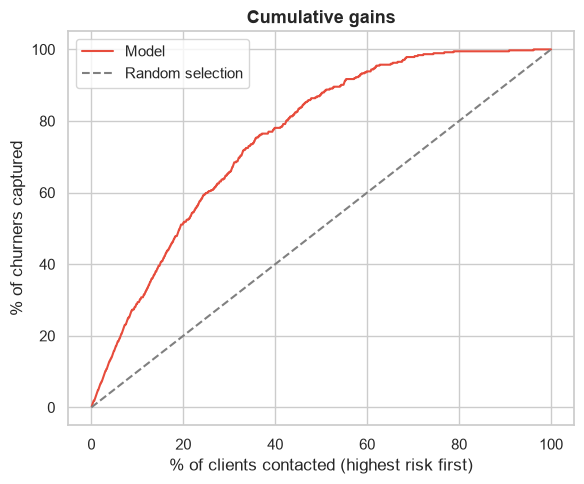

In [51]:
gains = (pd.DataFrame({'proba': test_proba, 'churn': y_test.values})
           .sort_values('proba', ascending=False).reset_index(drop=True))
gains['clients_%'] = (gains.index + 1) / len(gains) * 100
gains['churners_captured_%'] = gains['churn'].cumsum() / gains['churn'].sum() * 100

targets = [10, 20, 30, 50]
display(pd.DataFrame({
    'churners_captured_%': [gains.loc[math.ceil(len(gains) * p / 100) - 1, 'churners_captured_%'] for p in targets]
}, index=pd.Index(targets, name='top_%_of_clients_contacted')).round(1))

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(gains['clients_%'], gains['churners_captured_%'], color='#E74C3C', label='Model')
ax.plot([0, 100], [0, 100], linestyle='--', color='grey', label='Random selection')
ax.set_xlabel('% of clients contacted (highest risk first)')
ax.set_ylabel('% of churners captured')
ax.set_title('Cumulative gains', fontsize=13, weight='bold')
ax.legend()
plt.tight_layout()
fig.savefig('images/cumulative_gains.png', dpi=150, bbox_inches='tight')
plt.show()

Contacting only the 20% of clients with the highest predicted risk captures ~52% of the churners, about 2.6 times what a random selection would achieve. With 50% of clients, 88% of churners are reached.

### 8.5 What drives churn

Besides the odds ratios (7.3), we measure how much the model's ROC-AUC drops when each variable group is randomly shuffled on the test set (permutation importance). It measures how much the model relies on each variable group for its predictions.

,importance,std
tenure,0.100,0.010
InternetService,0.050,0.006
Contract,0.043,0.005
Add-on services,0.007,0.002
Phone (PhoneService + MultipleLines),0.004,0.002
PaymentMethod,0.002,0.002


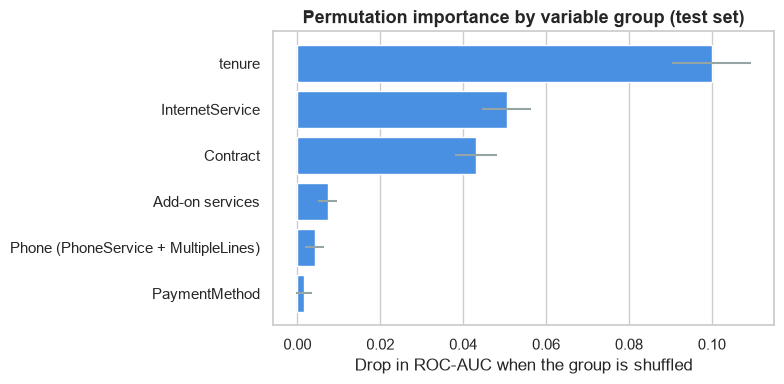

In [52]:
groups = {
    'tenure': ['tenure'],
    'InternetService': ['InternetService_Fiber optic', 'InternetService_No'],
    'Contract': ['Contract_One year', 'Contract_Two year'],
    'Add-on services': ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'],
    'Phone (PhoneService + MultipleLines)': ['PhoneService', 'MultipleLines'],
    'PaymentMethod': [c for c in X_test_f.columns if c.startswith('PaymentMethod')],
}
rng = np.random.default_rng(RANDOM_STATE)
base_auc = roc_auc_score(y_test, test_proba)

rows = {}
for gname, cols in groups.items():
    drops = []
    for _ in range(10):
        Xp = X_test_f.copy()
        Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]   # shuffle the whole group together
        drops.append(base_auc - roc_auc_score(y_test, final_model.predict_proba(Xp)[:, 1]))
    rows[gname] = {'importance': np.mean(drops), 'std': np.std(drops)}
group_imp = pd.DataFrame(rows).T.sort_values('importance', ascending=False)
display(group_imp.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(group_imp.index, group_imp['importance'], xerr=group_imp['std'], color='#4A90E2', ecolor='#95A5A6')
ax.invert_yaxis()
ax.set_xlabel('Drop in ROC-AUC when the group is shuffled')
ax.set_title('Permutation importance by variable group (test set)', fontsize=13, weight='bold')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

`tenure` is by far the variable the model relies on most (a drop of ~0.10 in ROC-AUC when shuffled), followed by `InternetService` (~0.05) and `Contract` (~0.04), the remaining groups are below 0.01. Variables are shuffled by group so multi-category variables are measured as a whole. Correlated variables share importance, so the ranking is a guide, not exact effects.

### 8.6 Conclusions and recommendations

* **The model works as a risk-ranking tool with probabilities that track observed churn rates:** ROC-AUC 0.85, PR-AUC 0.67 (random: 0.27) and Brier 0.135 (vs 0.195 for the base rate) on the test set. Contacting the clients with a positive expected value (44% of the base) captures 79% of the churners and outperforms the fixed-size rules. Against ranking by probability at the same 44%, the advantage is small (~1.7k USD, about 3%) and its interval includes zero (8.3).
* **Who is at risk:** new clients (the first months), on month-to-month contracts, with fiber optic and paying by electronic check (although it adds little to the model's predictions). In the EDA, clients with 0–6 months of tenure and monthly charges above 85 USD churned at 78%.
* **Recommendations** (based on associations in the data, to be validated with experiments):
  1. Focus retention efforts on the first months of the relationship (observed churn is 59% in the first three months).
  2. Encourage migration to one- or two-year contracts, which are associated with much lower odds of churn (0.50 and 0.26). This could be a reverse causality issue, where loyal clients choose longer contracts.
  3. Review the fiber optic service: its churn odds are 2.5 times those of DSL after controlling for contract and other variables, but since MonthlyCharges is excluded this includes the price tier, and the data cannot separate price from service quality.
  4. Promote technical support and online security, associated with lower churn (0.71 and 0.68), and automatic payment methods over electronic check (although it adds little to the model's predictions).
* **Characteristics that show no statistically significant independent effect once other variables are controlled**: being a senior citizen, having a partner and gender.

### 8.7 Limitations and next steps

* The data is a single snapshot of 7,043 clients: there is no time dimension, so the model has not been validated on a later period, which is how it would be used in production.
* The data is a sample provided by IBM. A 26.5% churn rate might be unrealistic.
* The model's probabilities are calibrated to this sample's 26.5% base rate. With a lower real churn rate the intercept must be recalibrated: in a simulation, the expected value rule contacts 27% of clients at 10% churn and 4% at 2%, versus 44% here.
* With these assumptions contacting every client is already profitable (about +11 USD per client), which shows the assumptions are generous.
* The results show associations, not causes. For example, fiber optic churn could reflect price, service quality or competition, and the data cannot tell which.
* The cost-benefit analysis uses illustrative assumptions (success rate, offer cost), and the share of clients to contact is sensitive to them (8.2). Client value is revenue, not margin. The calibration was checked on this snapshot, not on a later period.
* The model predicts who is likely to churn, not who would respond to an offer. Targeting should ideally rely on uplift (the incremental effect of the offer), which requires a controlled experiment.
* The target is whether the client already left (`Churn` = left within the last month), so the model ranks clients retrospectively and no prediction horizon is defined. The 12-month client value assumes the client would have stayed that long.
* Next steps: test interactions (for example tenure × contract), explore SHAP values, and run a controlled test of retention offers to measure their real effect.